# Simulación dosimétrica comparativa: vial de F-18 FDG con blindaje de plomo y tungsteno

## Tabla de contenidos

1. [Geometría del sistema](#1-geometría-del-sistema)
   - Capas radiales y axiales
   - Vial de vidrio y fuente
   - Detectores grupo A y B

2. [Materiales, detectores y fuente](#2-materiales-detectores-y-fuente)
   - Materiales personalizados
   - Configuración de la fuente

3. [Análisis de resultados](#3-análisis-de-resultados)
   - Lectura de datos
   - Consideraciones metodológicas
   - 3.1 Mapas de calor
   - 3.2 Validación estadística
   - 3.3 Dosis por detector
   - 3.4 Atenuación a través del blindaje
     - Perfil de dosis vs posición
     - Transmitancia

Este trabajo analiza la dosis recibida por un técnico durante el manejo y transporte nacional de un vial de F-18 FDG de 10 mCi, comparando dos contenedores blindados: el CT/A-30 (plomo + acero inoxidable) y el CT/A-30W (tungsteno). La simulación se realizó con GATE 10, que permite seguir el transporte de cada partícula a través de la geometría y registrar la energía depositada en detectores de tejido blando que representan distintas regiones del cuerpo del técnico.

Este notebook no contiene la simulación — eso lo hacen los scripts `vial_plomo.py` y `vial_tungsteno.py`. Acá se leen los resultados generados por GATE (archivos `.mhd/.raw` y `metadata_simulacion.json`) y se calculan las magnitudes de interés: distribución espacial de dosis, incertidumbre estadística, dosis equivalente en sieverts, perfil de atenuación a través del blindaje y transmitancia por detector.

## 1. Geometría del sistema

Se simularon dos contenedores blindados para el mismo radiofármaco. El CT/A-30 usa plomo como blindaje principal con una carcasa exterior de acero inoxidable. El CT/A-30W usa tungsteno. Las dimensiones de cada uno se obtuvieron de la ficha técnica del fabricante.

**Tabla 1 — Capas radiales** (medidas desde el eje central del cilindro)

| Capa | Radio int. | Radio ext. | Espesor | Radio int. | Radio ext. | Espesor |
|---|---|---|---|---|---|---|
| | **CT/A-30 (plomo)** | | | **CT/A-30W (tungsteno)** | | |
| Cavidad de aire | 0 mm | 16.5 mm | 16.5 mm | 0 mm | 16.75 mm | 16.75 mm |
| Blindaje principal | 16.5 mm | 48.5 mm | **32.0 mm (Pb)** | 16.75 mm | 46.25 mm | **29.5 mm (W)** |
| Carcasa de acero | 48.5 mm | 50.5 mm | 2.0 mm | — | — | — |

**Tabla 2 — Capas axiales** (medidas desde el centro del contenedor hacia cada tapa)

| Capa | Desde | Hasta | Espesor | Desde | Hasta | Espesor |
|---|---|---|---|---|---|---|
| | **CT/A-30 (plomo)** | | | **CT/A-30W (tungsteno)** | | |
| Cavidad de aire | 0 mm | 37.0 mm | 37.0 mm | 0 mm | 28.5 mm | 28.5 mm |
| Blindaje principal (tapa) | 37.0 mm | 55.75 mm | **18.75 mm (Pb)** | 28.5 mm | 50.25 mm | **21.75 mm (W)** |
| Carcasa de acero (tapa) | 55.75 mm | 57.75 mm | 2.0 mm | — | — | — |

**Tabla 3 — Vial de vidrio y fuente de agua** (igual en ambos contenedores)

| Elemento | Radio | Altura/espesor | Posición (centro en Z) |
|---|---|---|---|
| Pared del vial | 11.0 – 12.5 mm | 45.0 mm | z = −13.0 mm (plomo) / z = −4.5 mm (tungsteno) |
| Fondo del vial | 0 – 11.0 mm | 1.5 mm | z = −36.25 mm (plomo) / z = −27.75 mm (tungsteno) |
| Agua (10 mL, F-18 FDG) | 0 – 11.0 mm | 26.3 mm | z = −22.35 mm (plomo) / z = −13.85 mm (tungsteno) |

Algunas dimensiones presentan ligeras variaciones respecto a la ficha técnica, del orden de pocos milímetros, introducidas para evitar solapamientos geométricos en la simulación.

## 2. Materiales, detectores y fuente

Las librerías de GATE no incluyen todos los materiales necesarios, por lo que permite definirlos a partir de su composición atómica y densidad. En este proyecto se definieron manualmente el acero inoxidable, el plomo y el tungsteno. El resto de materiales (`G4_WATER`, `G4_AIR`, `G4_Pyrex_Glass`, `G4_TISSUE_SOFT_ICRP`) ya están predefinidos en Geant4 y no requieren definición adicional.

### Materiales utilizados en la simulación

**Tabla — Materiales personalizados** (definidos con `add_material_nb_atoms`, proporción por número de átomos)

| Material | Composición | Densidad | Contenedor | Dónde se usa |
|---|---|---|---|---|
| `StainlessSteel` | Fe : Cr : Ni = 70 : 20 : 10 | 7.81 g/cm³ | Plomo | Carcasa exterior |
| `Lead` | Pb (puro) | 11.4 g/cm³ | Plomo | Blindaje principal |
| `Tungsten` | W (puro) | 19.3 g/cm³ | Tungsteno | Blindaje principal |



Para cuantificar la dosis recibida en posiciones clave, se definen actores de dosis que registran la energía depositada en cada detector. 

**Tabla 4 — Detectores: grupo A (contacto con el contenedor)**

| Detector | Dimensiones | Material | Posición | Criterio |
|---|---|---|---|---|
| `det_palma` | 95×1×70 mm | G4_TISSUE_SOFT_ICRP | Y = −55 mm | Simula la palma apoyada sobre el contenedor |
| `det_dedos` | 1×40×70 mm | G4_TISSUE_SOFT_ICRP | X = +50 mm, Y = −35 mm | Simula los dedos rodeando el contenedor |

**Tabla 5 — Detectores: grupo B (técnico a 15 cm de la superficie)**

| Detector | Dimensiones | Material | Posición | Criterio |
|---|---|---|---|---|
| `det_torso` | 1×300×400 mm | G4_TISSUE_SOFT_ICRP | X = −200.5 mm | 15 cm desde la superficie externa (radio 50.5 mm) |
| `det_cabeza` | 1×130×170 mm | G4_TISSUE_SOFT_ICRP | X = −200.5 mm, Z = +450 mm | Misma distancia, a la altura de la cabeza |
| `det_manos` | 1×80×150 mm | G4_TISSUE_SOFT_ICRP | X = −200.5 mm, Y = +200 mm, Z = −180 mm | Misma distancia, a la altura de las manos |

Son especialmente importantes los detectores del grupo B, que emulan distintas regiones del cuerpo del técnico a 15 cm del contenedor. Todos tienen 1 mm de espesor en X (el eje que apunta hacia la fuente), lo que evita que la dosis se diluya al atravesar un volumen grueso. Los detectores del grupo A (`det_palma` y `det_dedos`) simulan el contacto directo durante la manipulación del vial.

La fuente radiactiva modelada es **F-18** (Flúor-18), en forma de FDG (fluorodesoxiglucosa),
disuelta uniformemente en los 10 mL de agua contenidos en el vial.

**Tabla 6 — Configuración de la fuente en la simulación**

| Parámetro | Valor |
|---|---|
| Partícula simulada | Ion (Z=9, A=18) — decaimiento gestionado por Geant4 (`enable_decay = True`) |
| Modo de decaimiento principal | Emisión β⁺ |
| Distribución espacial | Uniforme dentro del volumen de agua (`waterCil`) |
| Tipo de posición | Cilindro: radio 11.0mm, semi-altura 13.15mm |
| Distribución angular | Isotrópica (`iso`) |
| Physics list | `QGSP_BIC_EMZ` |


**Datos nucleares usados en el cálculo** (fuente: LNHB/CEA), necesarios para la
energía media emitida por decaimiento que usa la simulación:

| Parámetro | Valor | Uso en el código |
|---|---|---|
| Rama β⁺ | 96.86% | Fracción de decaimientos que emiten positrón |
| Energía media del positrón | 249.5 keV | Aporta a la energía media por decaimiento |
| Fotones de aniquilación por decaimiento | 1.9372 (× 511 keV) | Aporta a la energía media por decaimiento |

$$E_{media} = 0.9686 \times 0.2495\ \text{MeV} + 1.9372 \times 0.511\ \text{MeV} = 1.2312\ \text{MeV/decaimiento}$$



## 3. Análisis de resultados

Los resultados se analizan en cuatro etapas: visualización espacial de la dosis (mapas de calor), validación estadística (incertidumbre), cuantificación de la dosis recibida por cada detector (Gy/Sv), y atenuación a través del blindaje (perfil y transmitancia).

### Lectura de datos

Se definen las rutas donde GATE almacenó los resultados y se cargan los metadatos de la simulación.

In [5]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# --- Los dos contenedores a comparar ---
CONTENEDORES = {
    "Plomo (CT/A-30)":      Path("./output_pb"),
    "Tungsteno (CT/A-30W)": Path("./output_tungsteno"),
}

TIEMPO_EXPOSICION_S = 3600.0  # 1 hora, ajustar según el escenario
W_R     = 1.0       # Gy -> Sv, 1.0 para fotones/electrones
BQ_POR_MCI = 3.7e7

def leer_mhd(ruta_mhd: Path):
    """Lee un par .mhd/.raw generado por GATE y devuelve (array numpy, spacing_mm)."""
    header = {}
    with open(ruta_mhd, "r") as f:
        for linea in f:
            if "=" in linea:
                clave, valor = linea.split("=", 1)
                header[clave.strip()] = valor.strip()

    dim_size = [int(x) for x in header["DimSize"].split()]
    spacing_key = "ElementSpacing" if "ElementSpacing" in header else "ElementSize"
    spacing_mm = [float(x) for x in header[spacing_key].split()]

    tipos = {"MET_FLOAT": np.float32, "MET_DOUBLE": np.float64}
    dtype = tipos.get(header.get("ElementType", "MET_FLOAT"), np.float32)

    ruta_raw = ruta_mhd.parent / header["ElementDataFile"]
    datos = np.fromfile(ruta_raw, dtype=dtype)
    return datos.reshape(dim_size[::-1]), spacing_mm  # (Z, Y, X)


def buscar_archivo(carpeta: Path, nombre_actor: str, sufijo: str):
    """Tolera el prefijo largo que agrega GATE en algunas versiones."""
    candidatos = list(carpeta.glob(f"*{nombre_actor}-{sufijo}.mhd"))
    return candidatos[0] if candidatos else None

Se definen los parámetros de la simulación, las rutas de resultados y las funciones de lectura. Los archivos `.mhd/.raw` generados por GATE requieren lectura binaria antes de poder analizarlos.

### Consideraciones metodológicas

El número real de decaimientos en 1 hora a 10 mCi es:

$$N_{real} = 10\ \text{mCi} \times 3.7 \times 10^7\ \text{Bq/mCi} \times 3600\ \text{s} = 1.33 \times 10^{12}\ \text{decaimientos}$$

Simular ese número es computacionalmente inviable. Por eso se simula una fracción representativa y se aplica un **factor de escala** que magnifica los resultados proporcionalmente:

$$\text{factor} = \frac{A \times t}{N_{primarios}} $$

Este factor escala la amplitud de los resultados pero no su forma espacial ni las relaciones relativas entre detectores.

Como la simulación es estadística, pocos primarios producen resultados ruidosos aunque el factor de escala sea correcto. Por eso se evalúa la **incertidumbre relativa** de cada detector. Se tomará como aceptable resultados con incertidumbre menor al 10%.

### 3.1 Mapas de calor
Distribución espacial de la dosis en cada detector. Los detectores del grupo A (palma y dedos) muestran mapas densos por su cercanía a la fuente. Los del grupo B (torso, cabeza, manos) muestran pocos impactos.

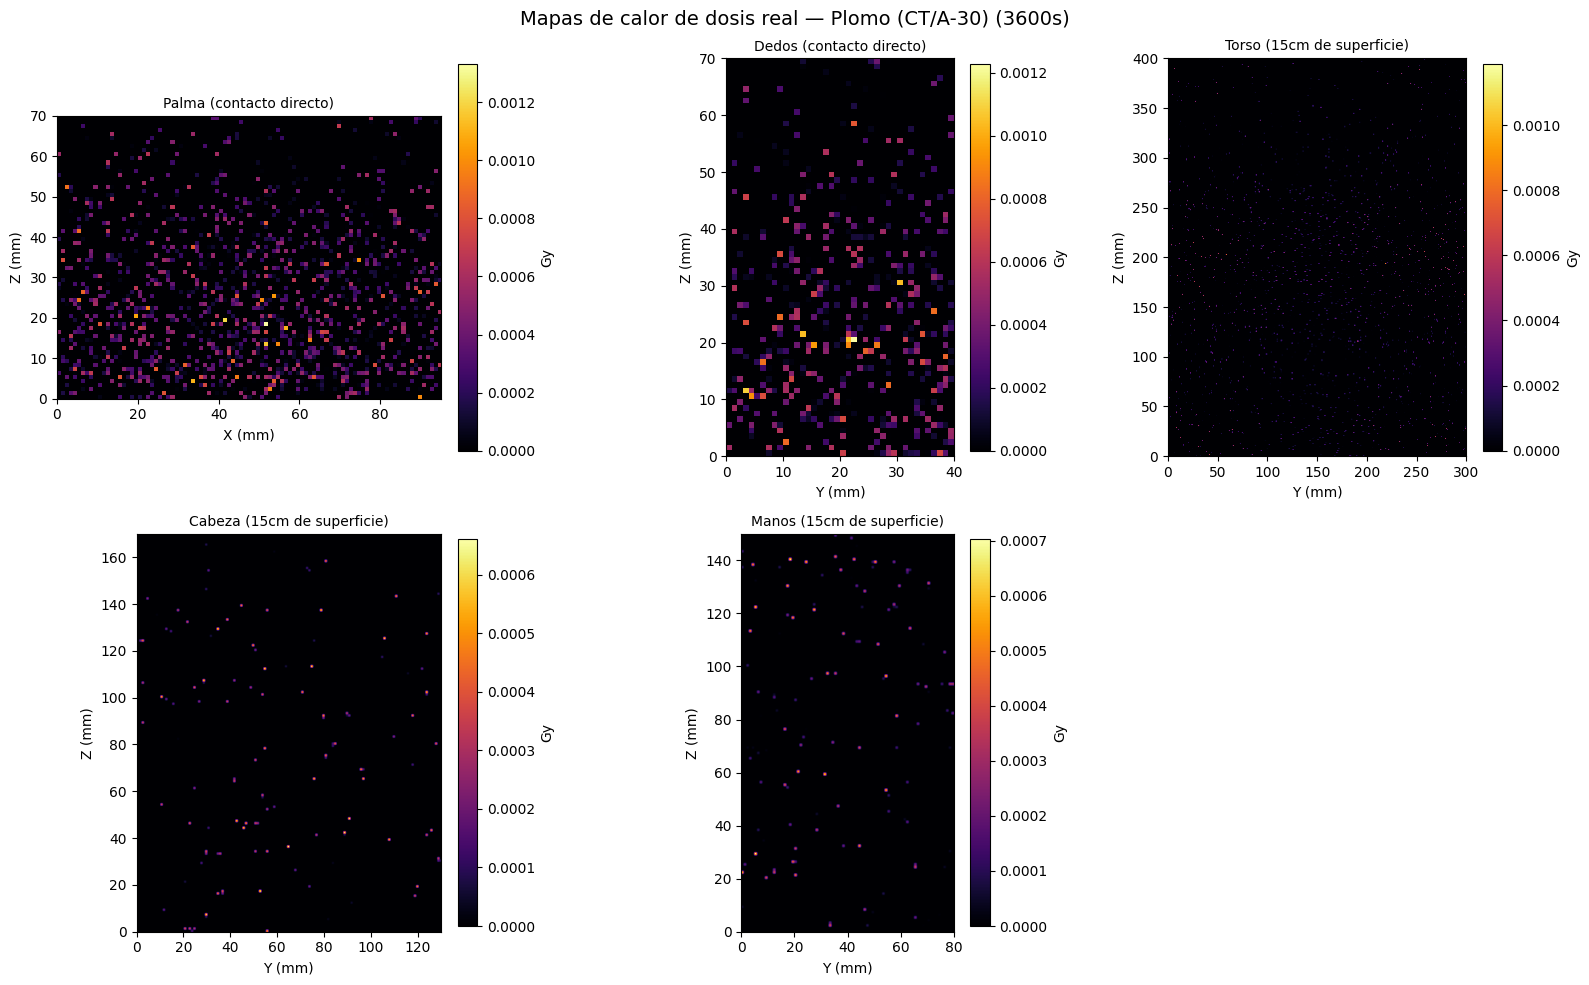

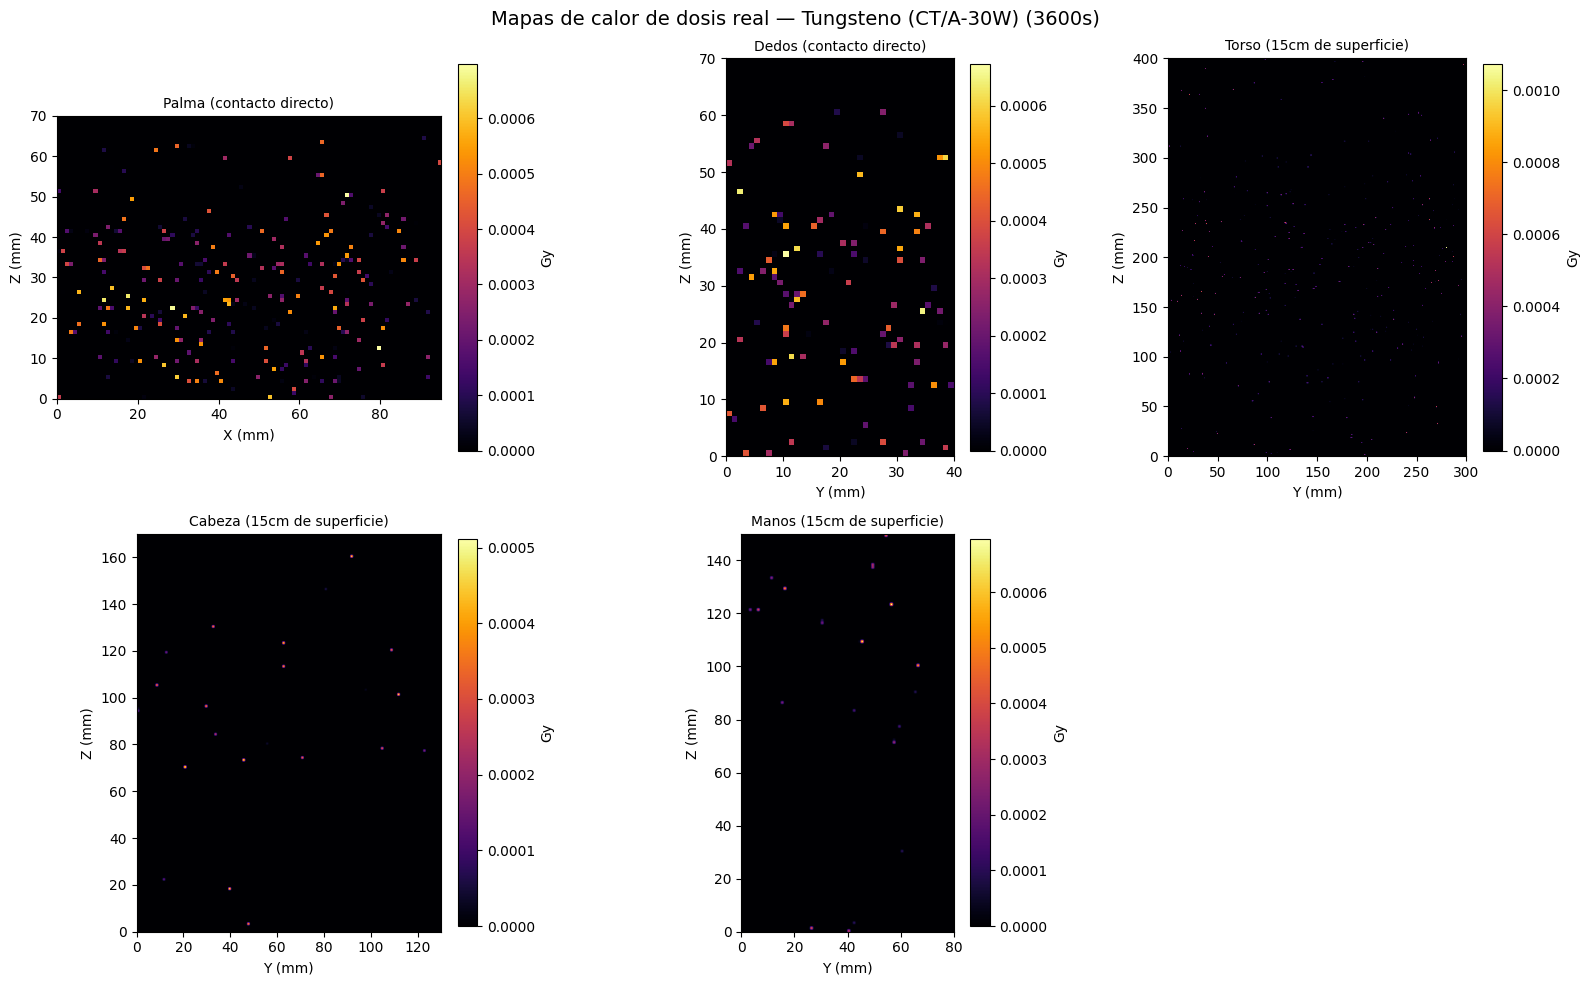

In [6]:
def mapa_calor_detector(ax, volumen, spacing_mm, titulo, unidad="Gy"):
    nz, ny, nx = volumen.shape
    if nz == 1:
        datos_2d = volumen[0, :, :]
        sp_a, sp_b = spacing_mm[1], spacing_mm[2]
        etiqueta_x, etiqueta_y = "Y (mm)", "X (mm)"
    elif ny == 1:
        datos_2d = volumen[:, 0, :]
        sp_a, sp_b = spacing_mm[0], spacing_mm[2]
        etiqueta_x, etiqueta_y = "Z (mm)", "X (mm)"
    else:
        datos_2d = volumen[:, :, 0]
        sp_a, sp_b = spacing_mm[0], spacing_mm[1]
        etiqueta_x, etiqueta_y = "Z (mm)", "Y (mm)"

    extent = [0, datos_2d.shape[1] * sp_b, 0, datos_2d.shape[0] * sp_a]
    im = ax.imshow(datos_2d, origin="lower", cmap="inferno", extent=extent, aspect="equal")
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel(etiqueta_y)
    ax.set_ylabel(etiqueta_x)
    plt.colorbar(im, ax=ax, label=unidad, fraction=0.046, pad=0.04)


DETECTORES = {
    "det_palma":  "Palma (contacto directo)",
    "det_dedos":  "Dedos (contacto directo)",
    "det_torso":  "Torso (15cm de superficie)",
    "det_cabeza": "Cabeza (15cm de superficie)",
    "det_manos":  "Manos (15cm de superficie)",
}

for etiqueta, carpeta in CONTENEDORES.items():
    meta_local = json.loads((carpeta / "metadata_simulacion.json").read_text(encoding="utf-8"))
    factor_escala_local = (meta_local["actividad_objetivo_mci"] * BQ_POR_MCI * TIEMPO_EXPOSICION_S) / meta_local["n_primarios_simulados"]

    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    axes = axes.flatten()
    for ax, (nombre, titulo) in zip(axes, DETECTORES.items()):
        ruta_dose = buscar_archivo(carpeta, f"dose_{nombre}", "dose")
        if ruta_dose is None:
            print(f"[AVISO] Falta dose_{nombre}-dose.mhd en {etiqueta}")
            ax.set_visible(False)
            continue
        datos, spacing = leer_mhd(ruta_dose)
        mapa_calor_detector(ax, datos * factor_escala_local, spacing, titulo)
    axes[-1].set_visible(False)
    fig.suptitle(f"Mapas de calor de dosis real — {etiqueta} ({TIEMPO_EXPOSICION_S:.0f}s)", fontsize=14)
    fig.tight_layout()
    plt.show()

**Lectura de los mapas de calor:** `det_palma` y `det_dedos` muestran distribuciones densas porque están en contacto directo con el contenedor y reciben muchos impactos. En cambio, `det_torso`, `det_cabeza` y `det_manos` (a 15 cm de la superficie, tras atravesar el blindaje completo) muestran mapas más apagados. 

### 3.2 Validación estadística

Como se mencionó antes, se tomarán como válidos resultados con incertidumbre relativa menor al 10%. Valores por encima indican que se necesitan más primarios simulados para que el resultado sea confiable.

La incertidumbre relativa combinada de un detector se calcula propagando la incertidumbre absoluta de cada vóxel y normalizando por la dosis total del detector:

$$\sigma_{rel} = \frac{\sqrt{\sum_i (\sigma_i \cdot D_i)^2}}{\sum_i D_i}$$

donde $D_i$ es la dosis en el vóxel $i$ y $\sigma_i$ es su incertidumbre relativa reportada por GATE. El numerador acumula la incertidumbre absoluta de cada vóxel en cuadratura (asumiendo independencia estadística entre vóxeles), y el denominador normaliza por la dosis total del detector para obtener una incertidumbre relativa global comparable entre detectores de distinto tamaño.

In [22]:
def incertidumbre_combinada(dosis_datos, incertidumbre_relativa_datos):
    incertidumbre_absoluta = incertidumbre_relativa_datos * dosis_datos
    dosis_total_para_ratio = float(np.sum(dosis_datos))
    if dosis_total_para_ratio <= 0:
        return None
    incertidumbre_absoluta_total = float(np.sqrt(np.sum(incertidumbre_absoluta ** 2)))
    return incertidumbre_absoluta_total / dosis_total_para_ratio


UMBRAL_INCERTIDUMBRE_ACEPTABLE = 0.10

resultados = {}  

for etiqueta, carpeta in CONTENEDORES.items():
    print(f"\n{'='*60}\n{etiqueta}\n{'='*60}")
    meta_local = json.loads((carpeta / "metadata_simulacion.json").read_text(encoding="utf-8"))
    factor_escala_local = (meta_local["actividad_objetivo_mci"] * BQ_POR_MCI * TIEMPO_EXPOSICION_S) / meta_local["n_primarios_simulados"]

    nombres_d, dosis_sv_l, incert_l = [], [], []
    for nombre, titulo in DETECTORES.items():
        ruta_dose = buscar_archivo(carpeta, f"dose_{nombre}", "dose")
        ruta_uncert = buscar_archivo(carpeta, f"dose_{nombre}", "dose_uncertainty")
        if ruta_dose is None:
            print(f"[AVISO] Falta {nombre}")
            continue

        datos_dose, _ = leer_mhd(ruta_dose)
        dosis_gy_real = float(np.mean(datos_dose)) * factor_escala_local
        dosis_sv_real = dosis_gy_real * W_R

        incert_rel = None
        if ruta_uncert is not None:
            datos_uncert, _ = leer_mhd(ruta_uncert)
            incert_rel = incertidumbre_combinada(datos_dose, datos_uncert)

        nombres_d.append(nombre)
        dosis_sv_l.append(dosis_sv_real)
        incert_l.append(incert_rel)

        veredicto = "N/A" if incert_rel is None else ("✓ OK" if incert_rel <= UMBRAL_INCERTIDUMBRE_ACEPTABLE else "✗ NECESITA MÁS PRIMARIOS")
        incert_txt = "N/A" if incert_rel is None else f"{incert_rel*100:.1f}%"
        print(f"{titulo:<28} {dosis_gy_real:.4e} Gy = {dosis_sv_real:.4e} Sv   Incertidumbre={incert_txt} {veredicto}")

    resultados[etiqueta] = {
        "detectores": nombres_d, "dosis_sv": dosis_sv_l, "incertidumbres": incert_l,
        "metadata": meta_local,
    }


Plomo (CT/A-30)
Palma (contacto directo)     5.6375e-05 Gy = 5.6375e-05 Sv   Incertidumbre=3.2% ✓ OK
Dedos (contacto directo)     4.5857e-05 Gy = 4.5857e-05 Sv   Incertidumbre=5.6% ✓ OK
Torso (15cm de superficie)   4.1372e-06 Gy = 4.1372e-06 Sv   Incertidumbre=2.8% ✓ OK
Cabeza (15cm de superficie)  1.7336e-06 Gy = 1.7336e-06 Sv   Incertidumbre=10.3% ✗ NECESITA MÁS PRIMARIOS
Manos (15cm de superficie)   2.5279e-06 Gy = 2.5279e-06 Sv   Incertidumbre=11.2% ✗ NECESITA MÁS PRIMARIOS

Tungsteno (CT/A-30W)
Palma (contacto directo)     9.5943e-06 Gy = 9.5943e-06 Sv   Incertidumbre=7.8% ✓ OK
Dedos (contacto directo)     1.1005e-05 Gy = 1.1005e-05 Sv   Incertidumbre=11.4% ✗ NECESITA MÁS PRIMARIOS
Torso (15cm de superficie)   8.4564e-07 Gy = 8.4564e-07 Sv   Incertidumbre=6.3% ✓ OK
Cabeza (15cm de superficie)  3.0169e-07 Gy = 3.0169e-07 Sv   Incertidumbre=23.7% ✗ NECESITA MÁS PRIMARIOS
Manos (15cm de superficie)   5.5044e-07 Gy = 5.5044e-07 Sv   Incertidumbre=24.8% ✗ NECESITA MÁS PRIMARIOS


### 3.3 Dosis por detector

La fuente emite partículas mediante decaimiento beta positivo. El positrón emitido se aniquila con un electrón del medio, produciendo dos fotones gamma de 511 keV. La dosis recibida por cada detector se expresa en sieverts. Para radiación gamma el factor de ponderación es W_R = 1, por lo que la dosis en gray y en sievert son numéricamente equivalentes.

Los valores de dosis deben interpretarse junto con su incertidumbre — los detectores con incertidumbre mayor al 10% (marcados con ✗) representan órdenes de magnitud correctos pero no valores exactos confiables.

In [8]:
def graficar_histograma_dosis(nombres, valores, incertidumbres, unidad, titulo):
    if not nombres:
        print(f"[AVISO] Sin datos para graficar: {titulo}")
        return
    fig, ax = plt.subplots(figsize=(9, 5.5))
    colores = plt.cm.viridis(np.linspace(0.15, 0.85, len(nombres)))
    barras = ax.bar(nombres, valores, color=colores)

    valores_pos = [v for v in valores if v > 0]
    if valores_pos:
        if max(valores_pos) / min(valores_pos) > 100:
            ax.set_yscale("log")
            ax.set_ylim(top=max(valores_pos) * 30)
        else:
            ax.set_ylim(top=max(valores_pos) * 1.25)
    else:
        print(f"[AVISO] Todos los valores son 0 en '{titulo}'.")
        ax.set_ylim(top=1)

    ax.set_ylabel(f"Dosis ({unidad})")
    ax.set_title(titulo, pad=15)
    ax.tick_params(axis="x", rotation=20)
    for barra, valor, incert in zip(barras, valores, incertidumbres):
        etiqueta = f"{valor:.2e}"
        if incert is not None:
            marca = "✓" if incert <= UMBRAL_INCERTIDUMBRE_ACEPTABLE else "✗"
            etiqueta += f" ({incert*100:.0f}% {marca})"
        ax.annotate(etiqueta, (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                    ha="center", va="bottom", fontsize=8, xytext=(0, 4), textcoords="offset points")
    fig.tight_layout()
    plt.show()

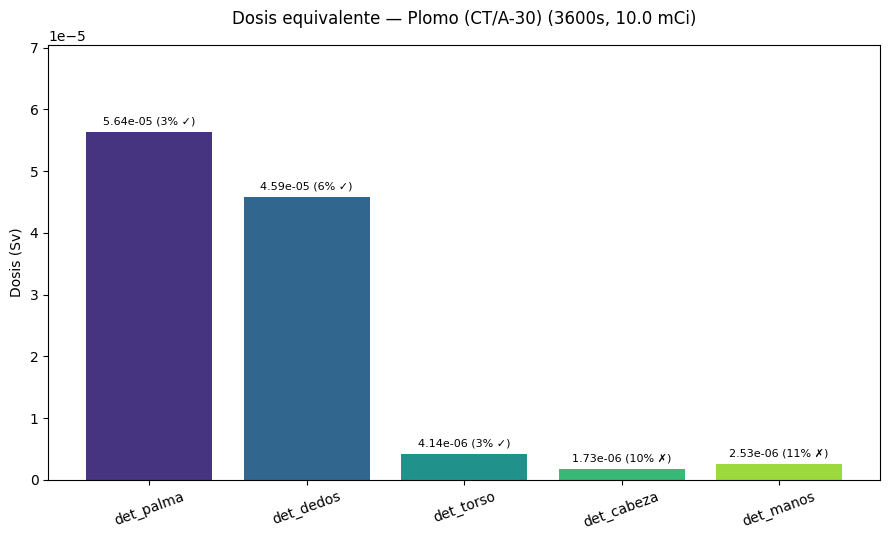

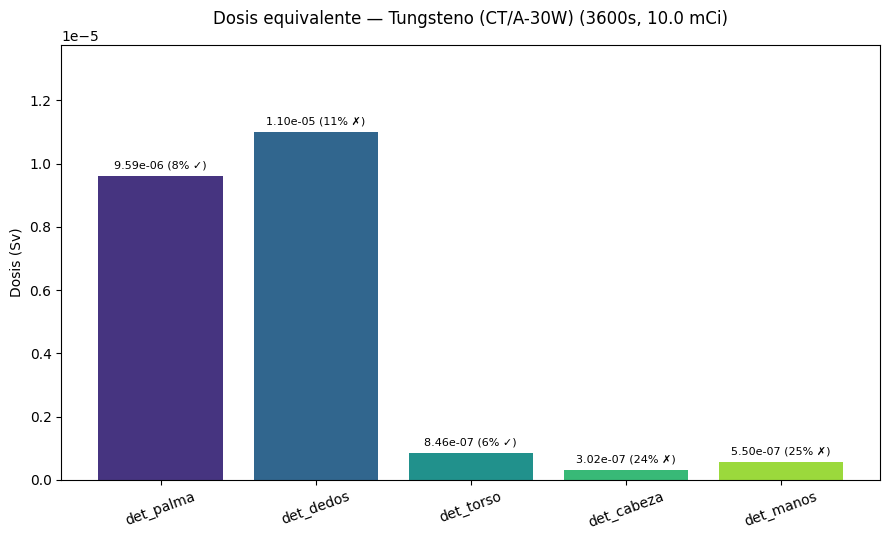

In [9]:
for etiqueta, r in resultados.items():
    meta_local = r["metadata"]
    graficar_histograma_dosis(
        r["detectores"], r["dosis_sv"], r["incertidumbres"], "Sv",
        f"Dosis equivalente — {etiqueta} ({TIEMPO_EXPOSICION_S:.0f}s, {meta_local['actividad_objetivo_mci']} mCi)"
    )

### 3.4 Atenuación a través del blindaje
#### Perfil de dosis vs posición

Muestra cómo decae la dosis al atravesar cada capa del blindaje desde la fuente hasta `det_torso` a 15 cm de la superficie. En general se verá mucho ruido en el exterior del blindaje si se mantiene la emulación con primarios entorno a los cien millones.

In [10]:
def reagrupar_perfil(perfil, spacing_eje, radio_externo_mm, factor_reagrupado=10, modo="suma"):
    
    n = perfil.shape[0]
    posiciones = (np.arange(n) - n / 2) * spacing_eje

    dentro_mask = np.abs(posiciones) <= radio_externo_mm
    fuera_mask = ~dentro_mask

    pos_dentro = posiciones[dentro_mask]
    val_dentro = perfil[dentro_mask]

    pos_fuera_pos = posiciones[fuera_mask & (posiciones > 0)]
    val_fuera_pos = perfil[fuera_mask & (posiciones > 0)]
    pos_fuera_neg = posiciones[fuera_mask & (posiciones < 0)]
    val_fuera_neg = perfil[fuera_mask & (posiciones < 0)]

    def _agrupar(pos, val, factor):
        n_completos = (len(val) // factor) * factor
        if n_completos == 0:
            return pos, val
        pos_r = pos[:n_completos].reshape(-1, factor).mean(axis=1)
        if modo == "promedio":
            val_r = val[:n_completos].reshape(-1, factor).mean(axis=1)
        else:
            val_r = val[:n_completos].reshape(-1, factor).sum(axis=1)
        return pos_r, val_r

    pos_fuera_pos_r, val_fuera_pos_r = _agrupar(pos_fuera_pos, val_fuera_pos, factor_reagrupado)
    pos_fuera_neg_r, val_fuera_neg_r = _agrupar(pos_fuera_neg[::-1], val_fuera_neg[::-1], factor_reagrupado)
    pos_fuera_neg_r, val_fuera_neg_r = pos_fuera_neg_r[::-1], val_fuera_neg_r[::-1]

    pos_final = np.concatenate([pos_fuera_neg_r, pos_dentro, pos_fuera_pos_r])
    val_final = np.concatenate([val_fuera_neg_r, val_dentro, val_fuera_pos_r])
    orden = np.argsort(pos_final)
    return pos_final[orden], val_final[orden]

In [11]:
def graficar_perfil_energia(datos, spacing_mm, eje, limites_geometria, titulo,
                             posicion_fuente=0.0, detectores_a_marcar=None, es_dosis=True):
    if eje == "radial":
        perfil = datos.mean(axis=(0, 1))  # intensiva -> promedio
        spacing_eje = spacing_mm[0]
    else:
        perfil = datos.mean(axis=(1, 2))
        spacing_eje = spacing_mm[2]

    radio_externo_mm = max(r1 for r0, r1 in limites_geometria.values())
    modo = "promedio" if es_dosis else "suma"
    posiciones, perfil_reagrupado = reagrupar_perfil(perfil, spacing_eje, radio_externo_mm,
                                                       factor_reagrupado=10, modo=modo)

    piso = max(perfil_reagrupado[perfil_reagrupado > 0].min() * 0.1, 1e-12) \
        if np.any(perfil_reagrupado > 0) else 1e-12
    perfil_graficar = np.where(perfil_reagrupado > 0, perfil_reagrupado, piso)

    if detectores_a_marcar:
        primera_pos = next(iter(detectores_a_marcar.values()))
        direccion = 1 if (primera_pos - posicion_fuente) >= 0 else -1
    else:
        direccion = 1

    posiciones_rel = posiciones - posicion_fuente
    mascara = (posiciones_rel * direccion) >= 0
    posiciones_rel = posiciones_rel[mascara]
    perfil_graficar = perfil_graficar[mascara]
    distancia_desde_fuente = posiciones_rel * direccion

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(distancia_desde_fuente, perfil_graficar, color="black", linewidth=1.2)
    ax.axhline(piso, color="gray", linestyle=":", linewidth=0.8, label="piso (sin estadística, ~0)")
    ax.axvline(0, color="tab:blue", linewidth=1.5, label="fuente (F-18)")

    if detectores_a_marcar:
        colores_lineas = ["red", "darkred", "firebrick", "crimson"]
        for (det_nombre, pos_abs), color in zip(detectores_a_marcar.items(), colores_lineas):
            dist_detector = (pos_abs - posicion_fuente) * direccion
            ax.axvline(dist_detector, color=color, linestyle="--", linewidth=1,
                       label=f"centro de {det_nombre}")

    ax.set_yscale("log")
    ax.set_xlabel("Distancia desde la fuente hacia el detector (mm)")
    ax.set_ylabel("Dosis (Gy, escala log)" if es_dosis else "Energía depositada (MeV, escala log)")
    ax.set_title(titulo)

    colores_region = {
        "agua": "#3355ff", "vidrio": "#00cccc", "cavidad_aire": "#a8d5ff",
        "plomo": "#7d7d7d", "acero": "#c9c9c9", "tungsteno": "#2e2e38",
    }
    etiquetas_usadas = set()
    for region, (r0, r1) in limites_geometria.items():
        color = colores_region.get(region, "#dddddd")
        a = (direccion * r0 - posicion_fuente) * direccion
        b = (direccion * r1 - posicion_fuente) * direccion
        etiqueta_reg = region if region not in etiquetas_usadas else None
        ax.axvspan(min(a, b), max(a, b), color=color, alpha=0.4, label=etiqueta_reg)
        etiquetas_usadas.add(region)

    ax.legend(loc="upper right", fontsize=8)
    fig.tight_layout()
    plt.show()

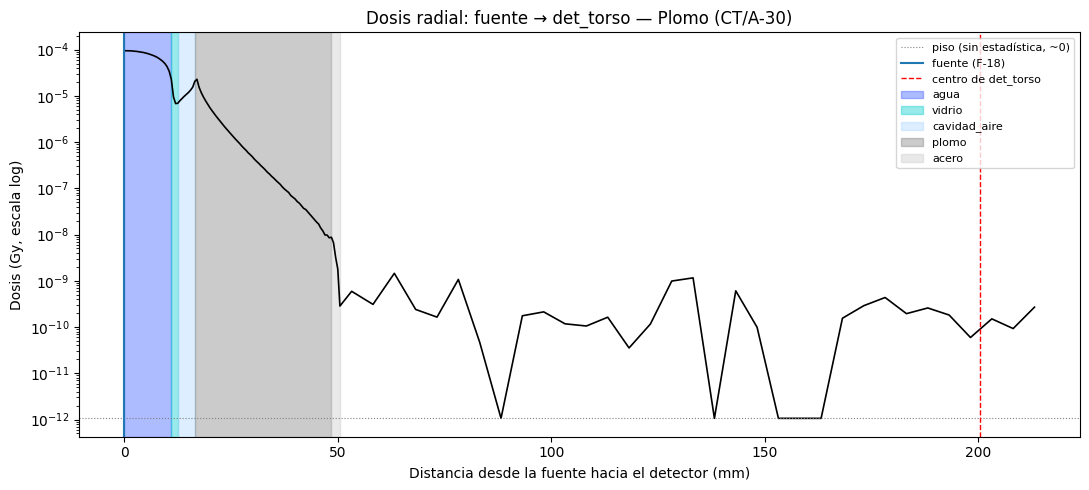

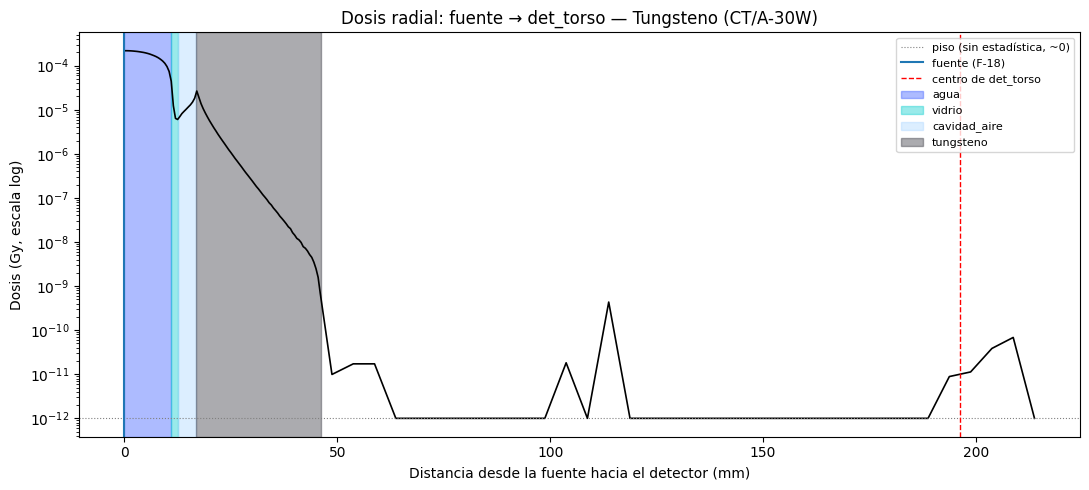

In [12]:
for etiqueta, carpeta in CONTENEDORES.items():
    meta_local = resultados[etiqueta]["metadata"]
    geometria_local = meta_local.get("geometria", {})

    ruta_perfil = buscar_archivo(carpeta, "dose_perfil_radial", "dose")
    if ruta_perfil is not None and "radial_mm" in geometria_local:
        datos_radial, spacing_radial = leer_mhd(ruta_perfil)
        limites = {k: v for k, v in geometria_local["radial_mm"].items() if isinstance(v, list)}
        pos_det = geometria_local["radial_mm"].get("det_torso_centro")
        graficar_perfil_energia(datos_radial, spacing_radial, "radial", limites,
                                 f"Dosis radial: fuente → det_torso — {etiqueta}",
                                 posicion_fuente=0.0,
                                 detectores_a_marcar={"det_torso": pos_det}, es_dosis=True)
    else:
        print(f"[AVISO] No se encontró el perfil radial para {etiqueta}.")

#### Transmitancia por ángulo sólido

Fracción de la energía emitida por la fuente que llega a cada detector, normalizada por la fracción del ángulo sólido que cubre ese detector. Esto elimina el efecto del tamaño y distancia del detector, dejando solo la atenuación real del blindaje como variable.

$$T_{corr} = \frac{E_{dep,\ detector}}{E_{total} \times \frac{\Omega_{detector}}{4\pi}}$$

donde $\Omega_{detector}$  se calcula como:

$$\Omega = 4\arctan\left(\frac{ab}{d\sqrt{a^2 + b^2 + d^2}}\right)$$

con $a$, $b$ los semilados del detector y $d$ la distancia perpendicular desde la fuente. Con esta corrección, la transmitancia es comparable entre detectores de distinto tamaño y posición — representa únicamente la capacidad de atenuación del blindaje en cada dirección.

In [21]:
import numpy as np

def angulo_solido_rectangulo(a, b, d):
    """Ángulo sólido exacto subtendido por un rectángulo de lados 2a x 2b
    visto desde una distancia d perpendicular a su centro (sr).
    Fórmula de Van Oosterom & Strackee (1983)."""
    x = a / d
    y = b / d
    return 4 * np.arctan(x * y / np.sqrt(1 + x**2 + y**2))

# Posición del centro de la fuente (aproximación puntual)
fuente = np.array([0.0, 0.0, -22.35])  # mm

# Geometría de cada detector: mitad de cada dimensión y distancia perpendicular
# (distancia desde la fuente al plano del detector, en la dirección del eje delgado)
geometria_detectores = {
    #           semilado_a  semilado_b  distancia_perp (mm)
    "det_palma":  (47.5,  35.0,  abs(-55.0  - fuente[1])),   # eje delgado Y
    "det_dedos":  (20.0,  35.0,  abs( 50.0  - fuente[0])),   # eje delgado X
    "det_torso":  (150.0, 200.0, abs(-200.5 - fuente[0])),   # eje delgado X
    "det_cabeza": (65.0,  85.0,  abs(-200.5 - fuente[0])),   # eje delgado X
    "det_manos":  (40.0,  75.0,  abs(-200.5 - fuente[0])),   # eje delgado X
}

OMEGA_4PI = 4 * np.pi  # ángulo sólido total de la fuente (sr)

transmitancias_por_material = {}

for etiqueta, carpeta in CONTENEDORES.items():
    meta_local = resultados[etiqueta]["metadata"]
    energia_media_mev = meta_local["energia_media_por_decaimiento_MeV"]
    energia_total_emitida_mev = meta_local["n_primarios_simulados"] * energia_media_mev

    print(f"\n{etiqueta}")
    print(f"{'Detector':<28} {'T_bruta':>12} {'Ω/4π':>10} {'T_corr':>12}")
    print("-" * 65)

    trans_local = []
    for nombre, titulo in DETECTORES.items():
        ruta_edep = buscar_archivo(carpeta, f"dose_{nombre}", "edep")
        if ruta_edep is None:
            print(f"  [AVISO] Falta {nombre}")
            trans_local.append(None)
            continue

        datos_edep, _ = leer_mhd(ruta_edep)
        edep_total_mev = float(np.sum(datos_edep))
        t_bruta = edep_total_mev / energia_total_emitida_mev

        # Ángulo sólido del detector
        a, b, d = geometria_detectores[nombre]
        omega = angulo_solido_rectangulo(a, b, d)
        fraccion_omega = omega / OMEGA_4PI
        

        # Transmitancia corregida por ángulo sólido
        t_corr = t_bruta / fraccion_omega if fraccion_omega > 0 else None

        trans_local.append(t_corr)
        print(f"  {titulo:<26} {t_bruta:>12.4e} {fraccion_omega:>10.4e} {t_corr:>12.4e}")
       

    transmitancias_por_material[etiqueta] = trans_local


Plomo (CT/A-30)
Detector                          T_bruta       Ω/4π       T_corr
-----------------------------------------------------------------
  Palma (contacto directo)     1.4692e-06 1.1413e-01   1.2873e-05
  Dedos (contacto directo)     5.0318e-07 6.8316e-02   7.3655e-06
  Torso (15cm de superficie)   1.9456e-06 1.3904e-01   1.3993e-05
  Cabeza (15cm de superficie)   1.5015e-07 3.8408e-02   3.9093e-06
  Manos (15cm de superficie)   1.1888e-07 2.1836e-02   5.4442e-06

Tungsteno (CT/A-30W)
Detector                          T_bruta       Ω/4π       T_corr
-----------------------------------------------------------------
  Palma (contacto directo)     2.5003e-07 1.1413e-01   2.1908e-06
  Dedos (contacto directo)     1.2075e-07 6.8316e-02   1.7676e-06
  Torso (15cm de superficie)   3.9767e-07 1.3904e-01   2.8601e-06
  Cabeza (15cm de superficie)   2.6129e-08 3.8408e-02   6.8030e-07
  Manos (15cm de superficie)   2.5885e-08 2.1836e-02   1.1854e-06


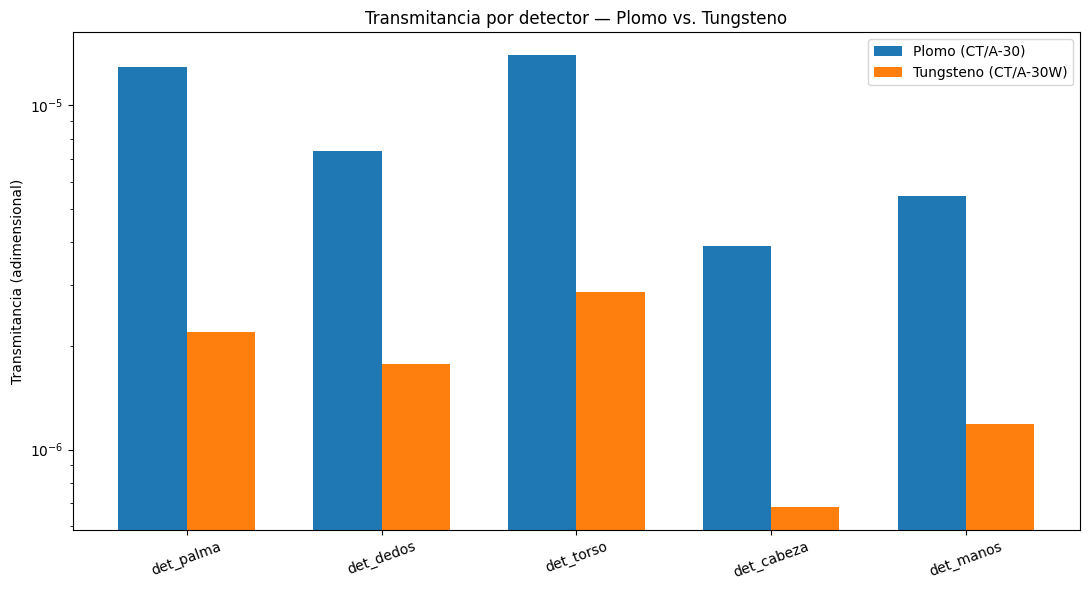

In [23]:
fig, ax = plt.subplots(figsize=(11, 6))
nombres_x = list(DETECTORES.keys())
x = np.arange(len(nombres_x))
ancho = 0.35

for i, (etiqueta, trans) in enumerate(transmitancias_por_material.items()):
    valores = [t if t is not None else 0 for t in trans]
    ax.bar(x + (i - 0.5) * ancho, valores, ancho, label=etiqueta)

ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(nombres_x, rotation=20)
ax.set_ylabel("Transmitancia (adimensional)")
ax.set_title("Transmitancia por detector — Plomo vs. Tungsteno")
ax.legend()
fig.tight_layout()
plt.show()

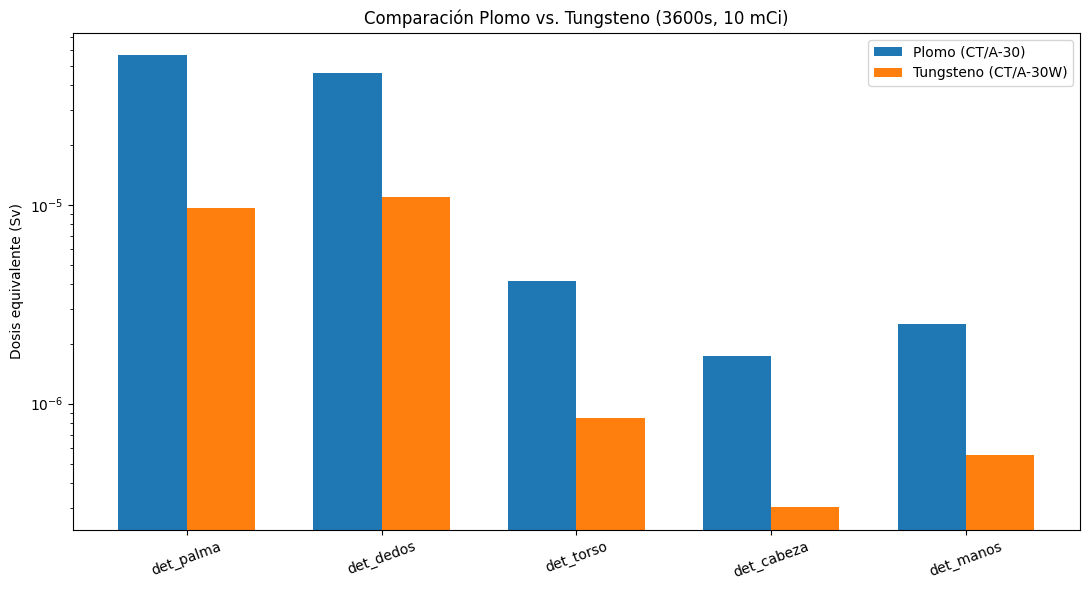

In [18]:
fig, ax = plt.subplots(figsize=(11, 6))
nombres_x = list(DETECTORES.keys())
x = np.arange(len(nombres_x))
ancho = 0.35

for i, (etiqueta, r) in enumerate(resultados.items()):
    # alinear por nombre de detector, por si a alguno le faltan datos en un material
    valores = [r["dosis_sv"][r["detectores"].index(n)] if n in r["detectores"] else 0 for n in nombres_x]
    ax.bar(x + (i - 0.5) * ancho, valores, ancho, label=etiqueta)

ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(nombres_x, rotation=20)
ax.set_ylabel("Dosis equivalente (Sv)")
ax.set_title(f"Comparación Plomo vs. Tungsteno ({TIEMPO_EXPOSICION_S:.0f}s, 10 mCi)")
ax.legend()
fig.tight_layout()
plt.show()